## ⚙️ Load the GROMACS–PLUMED Environment

Loads the required **compiler, MPI, CUDA, GROMACS, and PLUMED environment** on ACCRE and makes the configured GROMACS–PLUMED installation available within the notebook for subsequent HREMD setup and simulations.

In [42]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


In [43]:
load_gmx_plumed()

## 🧬 Generate the 64-Replica REST2/HREMD Setup

A **custom 64-replica λ ladder** was generated for the full REST2/HREMD setup.

- Defines the **number of replicas, base temperature, and maximum REST2 temperature**.
- Calculates the corresponding **λ values and effective temperatures**.
- Uses a **non-uniform λ distribution with denser spacing near λ = 1.0**.
- Saves the complete λ ladder to `rest2_lambdas.dat`.
- Creates a separate directory for each of the **64 replicas**.
- Generates a **partially tempered topology** for each λ using PLUMED.
- Builds the corresponding GROMACS `topol.tpr` for every replica.
- Prepares all replicas **in parallel** and verifies that the complete 64-replica setup was generated successfully.

In [29]:
### import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

# ============================================================
# USER SETTINGS
# ============================================================

n_replicas = int(input("Enter number of replicas [64]: ") or 64)
T0 = float(input("Enter base temperature T0 K [310]: ") or 310.0)
T_max = float(input("Enter max REST2 temperature Tmax K [520]: ") or 520.0)
max_workers = int(input("Enter parallel workers [64]: ") or 64)

# ============================================================
# FILE PATHS
# ============================================================

base_dir = "Hamiltonian"

hot_top = "2a/processed_selected.top"
gro_file = "Prep/b4md.gro"
mdp_file = "grompp.mdp"
lambda_file = "rest2_lambdas.dat"

# ============================================================
# CHECK INPUT FILES
# ============================================================

for f in [hot_top, gro_file, mdp_file]:
    if not os.path.exists(f):
        raise FileNotFoundError(f"Missing required file: {f}")

print("✅ All required files found")

os.makedirs(base_dir, exist_ok=True)

# ============================================================
# GENERATE REST2 LAMBDA LADDER
# Geometric shape with flipped density:
# dense near λ = 1.0, sparse toward λmin
# ============================================================

if n_replicas < 2:
    raise ValueError("n_replicas must be at least 2")

if T_max <= T0:
    raise ValueError("T_max must be greater than T0")

lambda_max = 1.0
lambda_min = T0 / T_max

g = np.geomspace(lambda_min, lambda_max, n_replicas)
lambdas = lambda_min + lambda_max - g

temps = T0 / lambdas

with open(lambda_file, "w") as f:
    f.write("# REST2 lambda values\n")
    f.write("# Geometric ladder with flipped density\n")
    f.write("# Dense near lambda = 1.0, sparse near lambda_min\n")
    f.write("# One lambda per line\n")
    for lam in lambdas:
        f.write(f"{lam:.6f}\n")

print(f"✅ Wrote {lambda_file}")
print(f"✅ Replica count: {n_replicas}")
print(f"✅ Lambda range: {lambdas[0]:.6f} → {lambdas[-1]:.6f}")
print(f"✅ Temperature range: {temps[0]:.2f} K → {temps[-1]:.2f} K")

# ============================================================
# CREATE REPLICA DIRECTORIES
# ============================================================

replica_dirs = []

for i in range(1, n_replicas + 1):
    d = os.path.join(base_dir, f"lambda{i:03d}")
    os.makedirs(d, exist_ok=True)
    replica_dirs.append(d)

print(f"✅ Created/found {len(replica_dirs)} replica directories")

# ============================================================
# BUILD EACH REPLICA IN PARALLEL
# Step 1: topol.top from plumed partial_tempering
# Step 2: topol.tpr from grompp
# ============================================================

hot_top_abs = os.path.abspath(hot_top)

def build_replica(rep_dir, lam):
    cmd_top = (
        f"plumed partial_tempering {lam:.6f} "
        f"< {hot_top_abs} "
        f"> topol.top"
    )

    r1 = subprocess.run(
        cmd_top,
        cwd=rep_dir,
        shell=True,
        executable="/bin/bash",
        capture_output=True,
        text=True
    )

    if r1.returncode != 0:
        return rep_dir, False, "PLUMED partial_tempering", r1.stdout, r1.stderr

    cmd_tpr = (
        "gmx_mpi grompp "
        f"-f ../../{mdp_file} "
        f"-c ../../{gro_file} "
        "-p topol.top "
        "-o topol.tpr "
        "-maxwarn 1"
    )

    r2 = subprocess.run(
        cmd_tpr,
        cwd=rep_dir,
        shell=True,
        executable="/bin/bash",
        capture_output=True,
        text=True
    )

    if r2.returncode != 0:
        return rep_dir, False, "grompp", r2.stdout, r2.stderr

    return rep_dir, True, "OK", r2.stdout, r2.stderr


print(f"🛠️ Building topol.top + topol.tpr with {max_workers} parallel workers")

failed = []

with ThreadPoolExecutor(max_workers=max_workers) as executor:
    futures = [
        executor.submit(build_replica, d, lam)
        for d, lam in zip(replica_dirs, lambdas)
    ]

    for future in as_completed(futures):
        rep_dir, ok, step, stdout, stderr = future.result()

        if ok:
            print(f"✅ Finished {rep_dir}/topol.top and topol.tpr")
        else:
            print(f"\n❌ Failed in {rep_dir}")
            print(f"Failed step: {step}")
            print("STDOUT:")
            print(stdout)
            print("STDERR:")
            print(stderr)
            failed.append(rep_dir)

if failed:
    print("\nFailed replicas:")
    for d in failed:
        print(d)
    raise RuntimeError(f"Failed in {len(failed)} replicas")

# ============================================================
# FINAL CHECK
# ============================================================

n_top = sum(os.path.exists(os.path.join(d, "topol.top")) for d in replica_dirs)
n_tpr = sum(os.path.exists(os.path.join(d, "topol.tpr")) for d in replica_dirs)

print("\n✅ Final check")
print(f"topol.top files: {n_top}/{n_replicas}")
print(f"topol.tpr files: {n_tpr}/{n_replicas}")

print("\n🎯 REST2 setup complete")

Enter number of replicas [64]:  64
Enter base temperature T0 K [310]:  310
Enter max REST2 temperature Tmax K [520]:  520
Enter parallel workers [64]:  64


✅ All required files found
✅ Wrote rest2_lambdas.dat
✅ Replica count: 64
✅ Lambda range: 1.000000 → 0.596154
✅ Temperature range: 310.00 K → 520.00 K
✅ Created/found 64 replica directories
🛠️ Building topol.top + topol.tpr with 64 parallel workers
✅ Finished Hamiltonian/lambda020/topol.top and topol.tpr
✅ Finished Hamiltonian/lambda012/topol.top and topol.tpr
✅ Finished Hamiltonian/lambda025/topol.top and topol.tpr
✅ Finished Hamiltonian/lambda057/topol.top and topol.tpr
✅ Finished Hamiltonian/lambda013/topol.top and topol.tpr
✅ Finished Hamiltonian/lambda009/topol.top and topol.tpr
✅ Finished Hamiltonian/lambda019/topol.top and topol.tpr
✅ Finished Hamiltonian/lambda016/topol.top and topol.tpr
✅ Finished Hamiltonian/lambda024/topol.top and topol.tpr
✅ Finished Hamiltonian/lambda021/topol.top and topol.tpr
✅ Finished Hamiltonian/lambda036/topol.top and topol.tpr
✅ Finished Hamiltonian/lambda055/topol.top and topol.tpr
✅ Finished Hamiltonian/lambda061/topol.top and topol.tpr
✅ Finished 

## 📍 Visualize the 64-Replica λ Ladder

Visualizes the **geometric spacing of the 64 λ values**, with finer spacing near **λ = 1.0**, where small changes in λ are used to maintain good overlap between replicas, and progressively wider spacing at lower λ values, where stronger tempering allows broader conformational sampling.

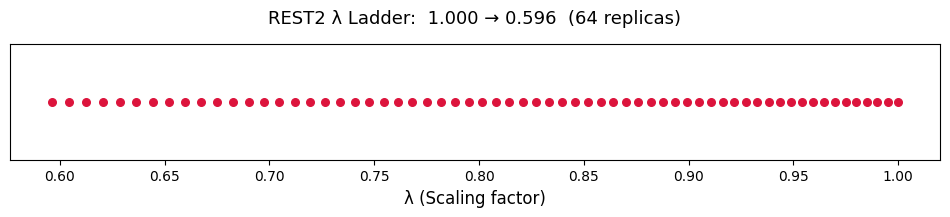

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# --- Load lambda values ---
with open("rest2_lambdas.dat") as f:
    lambdas = [float(line.strip()) for line in f if line.strip() and not line.startswith("#")]

# --- Plot number line ---
plt.figure(figsize=(12, 1.5))
plt.scatter(lambdas, np.zeros_like(lambdas), color='crimson', s=30)
plt.yticks([])
plt.xlim(min(lambdas) - 0.02, max(lambdas) + 0.02)
plt.xlabel("λ (Scaling factor)", fontsize=12)
plt.title(f"REST2 λ Ladder:  {lambdas[0]:.3f} → {lambdas[-1]:.3f}  ({len(lambdas)} replicas)", fontsize=13, pad=15)
plt.show()


## 📄 Create PLUMED Input for HREMD

Creates an **empty `plumed.dat` file** required to run the HREMD simulations with the PLUMED-enabled GROMACS setup. The REST2 scaling is already encoded in the replica-specific topologies, so no additional PLUMED bias is applied here.

In [31]:
import os

os.makedirs("Hamiltonian", exist_ok=True)

with open("Hamiltonian/plumed.dat", "w") as f:
    f.write("# Empty PLUMED file for HREMD\n")

print("Created Hamiltonian/plumed.dat")

Created Hamiltonian/plumed.dat


## 📄 Copy the PLUMED Input to All Replicas

Copies `plumed.dat` into each of the **64 λ replica directories**, ensuring that every replica has the PLUMED input required for the production HREMD run.

In [44]:
%%bash
for d in Hamiltonian/lambda*/; do
    cp Hamiltonian/plumed.dat "$d"
done

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us